# California Housing Regression Quickstart

This notebook is a compact, reproducible entry point for the regression project. It covers:

1. loading California Housing and checking data quality;
2. creating a fixed 70% / 15% / 15% split;
3. comparing raw features with three engineered ratio features;
4. selecting Ridge regularization with training-only 5-fold cross-validation;
5. recording validation/test metrics and predictions;
6. checking a NumPy gradient-descent Ridge implementation against scikit-learn.

> The test set is evaluated only after the feature set, model, and hyperparameters have been locked.

Run the notebook from the repository root or from the `notebooks/` directory. Outputs are written to `quickstart_results/`.

## 1. Setup

Install the experiment and notebook dependencies with:

```bash
python -m pip install -r requirements-notebook.txt
```

In [1]:
%matplotlib inline

from pathlib import Path
import json
import os
import platform
import sys
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

warnings.filterwarnings("ignore", category=FutureWarning)

ROOT = Path.cwd().resolve()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
if not (ROOT / "src").exists():
    raise RuntimeError("Run this notebook from the repository or notebooks directory.")
sys.path.insert(0, str(ROOT))
os.environ.setdefault("MPLCONFIGDIR", str(ROOT / ".cache" / "matplotlib"))

from src.config import FEATURE_COLUMNS, RANDOM_STATE, RIDGE_ALPHAS, TARGET_COLUMN
from src.data import build_data_profile, load_dataset, split_dataset
from src.evaluation import regression_metrics, save_predictions
from src.features import AddRatioFeatures, build_preprocessor
from src.linear_models import best_ridge_candidate, fit_candidate_models
from src.ridge_scratch import RidgeGradientDescent

QUICKSTART_DIR = ROOT / "quickstart_results"
PREDICTION_DIR = QUICKSTART_DIR / "predictions"
QUICKSTART_DIR.mkdir(parents=True, exist_ok=True)
PREDICTION_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_columns", 30)

print(f"Project root: {ROOT}")
print(f"Python: {platform.python_version()}")

Project root: D:\Myhomework\机器学习
Python: 3.14.6


## 2. Load the data

The repository includes a prepared local CSV. If it is absent, the notebook falls back to scikit-learn's official download helper.

In [2]:
data_path = ROOT / "data" / "california_housing.csv"

if data_path.exists():
    frame = load_dataset(data_path)
else:
    from sklearn.datasets import fetch_california_housing

    data_path.parent.mkdir(parents=True, exist_ok=True)
    housing = fetch_california_housing(
        data_home=str(ROOT / "data" / "raw"),
        download_if_missing=True,
        as_frame=True,
    )
    frame = housing.frame
    frame.to_csv(data_path, index=False, encoding="utf-8")

print(f"Rows: {len(frame):,}")
print(f"Features: {len(FEATURE_COLUMNS)}")
print(f"Target: {TARGET_COLUMN} (unit: 100,000 USD)")
print(f"Missing values: {int(frame.isna().sum().sum())}")
display(frame.head())

Rows: 20,640
Features: 8
Target: MedHouseVal (unit: 100,000 USD)
Missing values: 0


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


## 3. Create the fixed split

The same `random_state=42` split is used by both project members. The test set remains untouched during model selection.

In [3]:
split_frames, train_ids, validation_ids, test_ids = split_dataset(frame)
split_summary = pd.DataFrame(
    {name: {"rows": len(split)} for name, split in split_frames.items()}
).T
display(split_summary)

assert set(train_ids).isdisjoint(validation_ids)
assert set(train_ids).isdisjoint(test_ids)
assert set(validation_ids).isdisjoint(test_ids)
assert len(set(train_ids) | set(validation_ids) | set(test_ids)) == len(frame)
print("Split integrity check passed.")

,rows
train,14448
validation,3096
test,3096


Split integrity check passed.


## 4. Data quality and exploratory checks

In [4]:
profile = build_data_profile(frame)
display(
    profile[
        [
            "column",
            "missing",
            "mean",
            "std",
            "min",
            "median",
            "max",
            "skewness",
            "iqr_outlier_count",
        ]
    ].round(3)
)

print(f"Exact duplicate rows: {int(frame.duplicated().sum())}")
print(f"Observations at target cap (>= 4.99): {int((frame[TARGET_COLUMN] >= 4.99).sum())}")

,column,missing,mean,std,min,median,max,skewness,iqr_outlier_count
0,MedInc,0,3.871,1.900,0.500,3.535,15.000,1.647,681
1,HouseAge,0,28.639,12.586,1.000,29.000,52.000,0.060,0
2,AveRooms,0,5.429,2.474,0.846,5.229,141.909,20.698,511
3,AveBedrms,0,1.097,0.474,0.333,1.049,34.067,31.317,1424
4,Population,0,1425.477,1132.462,3.000,1166.000,35682.000,4.936,1196
5,AveOccup,0,3.071,10.386,0.692,2.818,1243.333,97.640,711
6,Latitude,0,35.632,2.136,32.540,34.260,41.950,0.466,0
7,Longitude,0,-119.570,2.004,-124.350,-118.490,-114.310,-0.298,0
8,MedHouseVal,0,2.069,1.154,0.150,1.797,5.000,0.978,1071


Exact duplicate rows: 0
Observations at target cap (>= 4.99): 994


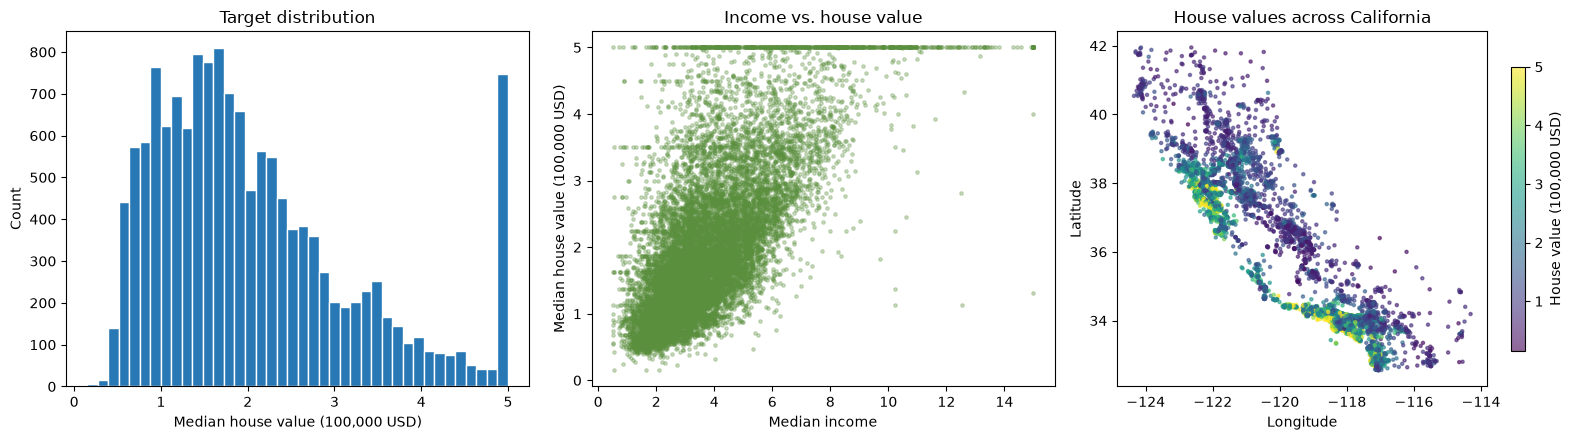

In [5]:
train_frame = split_frames["train"]
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

axes[0].hist(train_frame[TARGET_COLUMN], bins=40, color="#2878B5", edgecolor="white")
axes[0].set_title("Target distribution")
axes[0].set_xlabel("Median house value (100,000 USD)")
axes[0].set_ylabel("Count")

axes[1].scatter(
    train_frame["MedInc"],
    train_frame[TARGET_COLUMN],
    s=6,
    alpha=0.3,
    color="#5A8F3D",
)
axes[1].set_title("Income vs. house value")
axes[1].set_xlabel("Median income")
axes[1].set_ylabel("Median house value (100,000 USD)")

scatter = axes[2].scatter(
    train_frame["Longitude"],
    train_frame["Latitude"],
    c=train_frame[TARGET_COLUMN],
    cmap="viridis",
    s=5,
    alpha=0.6,
)
axes[2].set_title("House values across California")
axes[2].set_xlabel("Longitude")
axes[2].set_ylabel("Latitude")
fig.colorbar(scatter, ax=axes[2], shrink=0.8, label="House value (100,000 USD)")
fig.tight_layout()
fig.savefig(QUICKSTART_DIR / "eda_overview.png", dpi=180, bbox_inches="tight")
plt.show()

## 5. Feature engineering

Three features are appended to the eight original predictors:

$$
\text{BedroomRatio} = \frac{\text{AveBedrms}}{\text{AveRooms}+\epsilon}
$$

$$
\text{RoomsPerPerson} = \frac{\text{AveRooms}}{\text{AveOccup}+\epsilon}
$$

$$
\text{HouseholdsApprox} = \frac{\text{Population}}{\text{AveOccup}+\epsilon}
$$

The transformer is deterministic and never uses the target.

In [6]:
engineered = AddRatioFeatures().fit_transform(train_frame[FEATURE_COLUMNS])
display(engineered[["BedroomRatio", "RoomsPerPerson", "HouseholdsApprox"]].head())
print(f"Original feature count: {len(FEATURE_COLUMNS)}")
print(f"Engineered feature count: {engineered.shape[1]}")

,BedroomRatio,RoomsPerPerson,HouseholdsApprox
0,0.165833,1.970443,408.0
1,0.244617,2.185185,496.0
2,0.176140,2.190150,285.0
3,0.186420,2.682119,138.0
4,0.222083,2.089122,664.0


Original feature count: 8
Engineered feature count: 11


## 6. Fit linear models and select Ridge alpha

Linear Regression is the unregularized baseline. Ridge is tuned by 5-fold cross-validation **inside the training set**. Candidate selection between feature sets uses validation RMSE.

In [7]:
candidates, ranking, cv_results = fit_candidate_models(split_frames)
display(
    ranking[
        [
            "model",
            "feature_set",
            "validation_mae",
            "validation_rmse",
            "validation_r2",
            "best_alpha",
            "cv_rmse",
            "cv_rmse_std",
        ]
    ].round(4)
)
selected = next(candidate for candidate in candidates if candidate["selected"])
print(f"Selected by validation RMSE: {selected['key']}")

,model,feature_set,validation_mae,validation_rmse,validation_r2,best_alpha,cv_rmse,cv_rmse_std
2,Linear Regression,ratio,0.4918,0.6809,0.6442,NaN,NaN,NaN
3,Ridge Regression,ratio,0.4919,0.6816,0.6434,100.0,0.6822,0.0144
1,Ridge Regression,raw,0.5334,0.7354,0.5848,3.0,0.7246,0.0121
0,Linear Regression,raw,0.5335,0.7354,0.5848,NaN,NaN,NaN


Selected by validation RMSE: linear_ratio


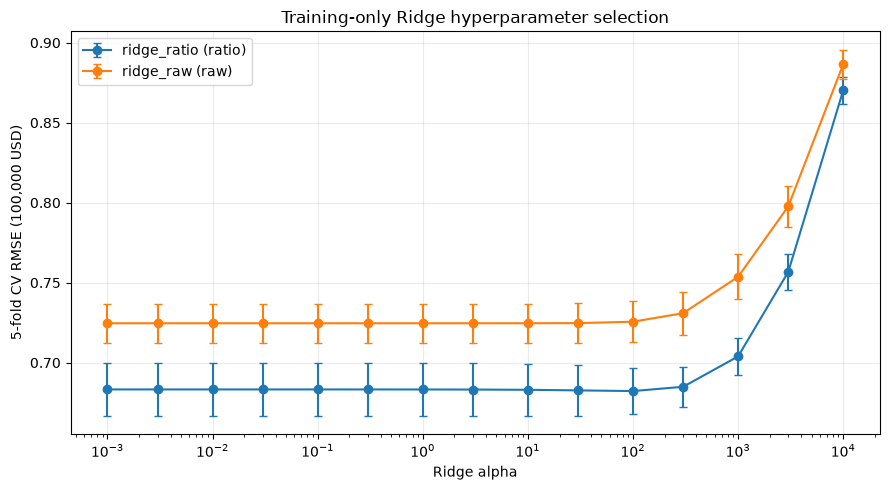

In [8]:
fig, ax = plt.subplots(figsize=(9, 5))
for (model_key, feature_set), group in cv_results.groupby(["model_key", "feature_set"]):
    ax.errorbar(
        group["alpha"],
        group["mean_validation_rmse"],
        yerr=group["std_validation_rmse"],
        marker="o",
        capsize=3,
        label=f"{model_key} ({feature_set})",
    )
ax.set_xscale("log")
ax.set_xlabel("Ridge alpha")
ax.set_ylabel("5-fold CV RMSE (100,000 USD)")
ax.set_title("Training-only Ridge hyperparameter selection")
ax.grid(alpha=0.25)
ax.legend()
fig.tight_layout()
fig.savefig(QUICKSTART_DIR / "ridge_alpha_selection.png", dpi=180, bbox_inches="tight")
plt.show()

## 7. Locked final evaluation and prediction records

The feature set, model, and Ridge alpha are now fixed. The test set is used once for the final reportable metrics.

In [9]:
X_sets = {
    name: split.loc[:, FEATURE_COLUMNS]
    for name, split in split_frames.items()
}
y_sets = {
    name: split[TARGET_COLUMN].to_numpy()
    for name, split in split_frames.items()
}
row_ids = {
    name: split["row_id"].to_numpy()
    for name, split in split_frames.items()
}

metric_rows = []
prediction_frames = {}
for candidate in candidates:
    prediction_frames[candidate["key"]] = {}
    for split_name in ("validation", "test"):
        prediction = candidate["pipeline"].predict(X_sets[split_name])
        prediction_frames[candidate["key"]][split_name] = save_predictions(
            PREDICTION_DIR,
            candidate["key"],
            split_name,
            row_ids[split_name],
            y_sets[split_name],
            prediction,
        )
        metric_rows.append(
            {
                "model_key": candidate["key"],
                "model": candidate["label"],
                "feature_set": candidate["feature_set"],
                "split": split_name,
                "best_alpha": candidate["best_alpha"],
                **regression_metrics(y_sets[split_name], prediction),
            }
        )

metrics = pd.DataFrame(metric_rows)
display(metrics[metrics["split"] == "test"].round(4))
metrics.to_csv(QUICKSTART_DIR / "metrics.csv", index=False, encoding="utf-8")

,model_key,model,feature_set,split,best_alpha,n_samples,mae,mse,rmse,r2
1,linear_raw,Linear Regression,raw,test,NaN,3096,0.5210,0.5203,0.7213,0.6066
3,ridge_raw,Ridge Regression,raw,test,3.0,3096,0.5210,0.5201,0.7212,0.6067
5,linear_ratio,Linear Regression,ratio,test,NaN,3096,0.4735,0.4195,0.6477,0.6828
7,ridge_ratio,Ridge Regression,ratio,test,100.0,3096,0.4737,0.4212,0.6490,0.6815


## 8. Feature-engineering ablation

,model,split,raw_rmse,ratio_rmse,delta_rmse,delta_rmse_percent,delta_r2
0,Linear Regression,validation,0.7354,0.6809,-0.0546,-7.4210,0.0593
1,Ridge Regression,validation,0.7354,0.6816,-0.0539,-7.3240,0.0586
2,Linear Regression,test,0.7213,0.6477,-0.0736,-10.2054,0.0762
3,Ridge Regression,test,0.7212,0.6490,-0.0722,-10.0146,0.0748


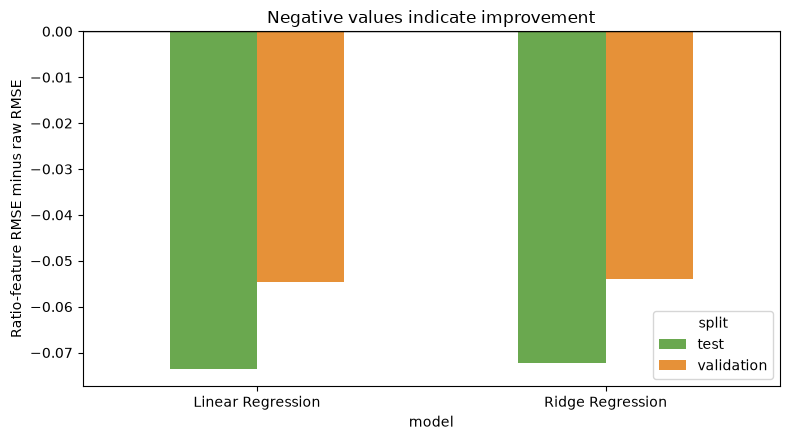

In [10]:
ablation_rows = []
for split_name in ("validation", "test"):
    for model_name in ("Linear Regression", "Ridge Regression"):
        raw = metrics[
            (metrics["split"] == split_name)
            & (metrics["model"] == model_name)
            & (metrics["feature_set"] == "raw")
        ].iloc[0]
        ratio = metrics[
            (metrics["split"] == split_name)
            & (metrics["model"] == model_name)
            & (metrics["feature_set"] == "ratio")
        ].iloc[0]
        ablation_rows.append(
            {
                "model": model_name,
                "split": split_name,
                "raw_rmse": raw["rmse"],
                "ratio_rmse": ratio["rmse"],
                "delta_rmse": ratio["rmse"] - raw["rmse"],
                "delta_rmse_percent": 100 * (ratio["rmse"] - raw["rmse"]) / raw["rmse"],
                "delta_r2": ratio["r2"] - raw["r2"],
            }
        )
ablation = pd.DataFrame(ablation_rows)
ablation.to_csv(QUICKSTART_DIR / "feature_engineering_ablation.csv", index=False)
display(ablation.round(4))

fig, ax = plt.subplots(figsize=(8, 4.5))
pivot = ablation.pivot(index="model", columns="split", values="delta_rmse")
pivot.plot(kind="bar", ax=ax, color=["#6AA84F", "#E69138"])
ax.axhline(0, color="black", linewidth=1)
ax.set_ylabel("Ratio-feature RMSE minus raw RMSE")
ax.set_title("Negative values indicate improvement")
ax.tick_params(axis="x", rotation=0)
fig.tight_layout()
fig.savefig(QUICKSTART_DIR / "feature_engineering_ablation.png", dpi=180, bbox_inches="tight")
plt.show()

## 9. NumPy Ridge from scratch

The custom implementation uses full-batch gradient descent. For a mean-squared objective `J = (1/m)||Xw+b-y||² + lambda||w||²`, the equivalent regularization is `lambda = alpha / m` relative to scikit-learn's residual-sum-of-squares objective.

,split,n_samples,mae,mse,rmse,r2
0,train,14448,0.4847,0.4539,0.6737,0.6612
1,validation,3096,0.4919,0.4645,0.6816,0.6434
2,test,3096,0.4737,0.4212,0.6490,0.6815


Converged: True | iterations: 3708 | alpha: 100.0 | lambda: 0.00692137


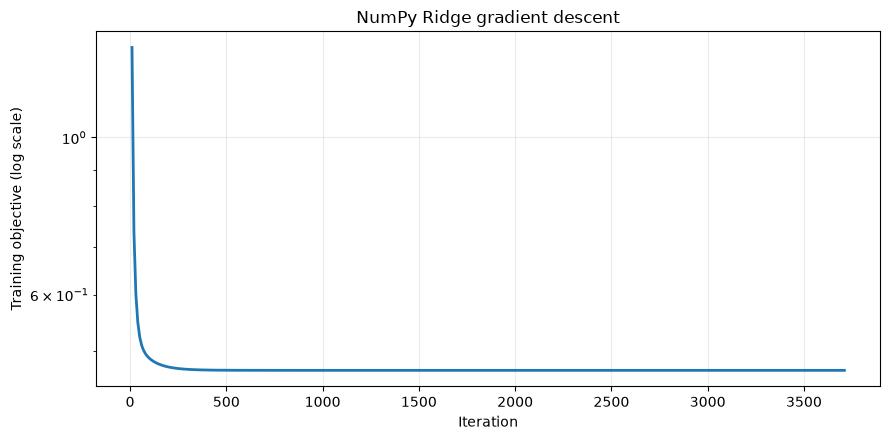

In [11]:
best_ridge = best_ridge_candidate(candidates)
preprocessor = build_preprocessor(best_ridge["feature_set"])
X_scaled = {
    "train": np.asarray(preprocessor.fit_transform(X_sets["train"], y_sets["train"])),
    "validation": np.asarray(preprocessor.transform(X_sets["validation"])),
    "test": np.asarray(preprocessor.transform(X_sets["test"])),
}
lambda_custom = best_ridge["best_alpha"] / len(y_sets["train"])
scratch_model = RidgeGradientDescent(
    lambda_=lambda_custom,
    learning_rate=0.05,
    max_iter=5_000,
    tolerance=1e-7,
)
scratch_model.fit(X_scaled["train"], y_sets["train"])

scratch_rows = []
for split_name in ("train", "validation", "test"):
    prediction = scratch_model.predict(X_scaled[split_name])
    if split_name in ("validation", "test"):
        save_predictions(
            PREDICTION_DIR,
            "numpy_ridge_gd",
            split_name,
            row_ids[split_name],
            y_sets[split_name],
            prediction,
        )
    scratch_rows.append(
        {"split": split_name, **regression_metrics(y_sets[split_name], prediction)}
    )
scratch_metrics = pd.DataFrame(scratch_rows)
display(scratch_metrics.round(4))
print(
    f"Converged: {scratch_model.converged_} | iterations: {scratch_model.n_iter_} | "
    f"alpha: {best_ridge['best_alpha']} | lambda: {lambda_custom:.8f}"
)

fig, ax = plt.subplots(figsize=(9, 4.5))
iterations = np.arange(1, len(scratch_model.loss_history_) + 1) * scratch_model.record_every
ax.plot(iterations, scratch_model.loss_history_, linewidth=2)
ax.set_yscale("log")
ax.set_xlabel("Iteration")
ax.set_ylabel("Training objective (log scale)")
ax.set_title("NumPy Ridge gradient descent")
ax.grid(alpha=0.25)
fig.tight_layout()
fig.savefig(QUICKSTART_DIR / "numpy_ridge_loss.png", dpi=180, bbox_inches="tight")
plt.show()

## 10. Error analysis and output manifest

The selected A-side model is analyzed by true-price band. High-value observations, especially those at the 5.0 target cap, are expected to have larger errors.

,price_band,n_samples,mae,rmse,mean_bias
0,<1.5,1124,0.4203,0.5267,0.2839
1,1.5-3.0,1394,0.3478,0.4479,0.0842
2,3.0-4.99,437,0.7501,0.9470,-0.6757
3,>=4.99,141,1.2831,1.4955,-0.9292


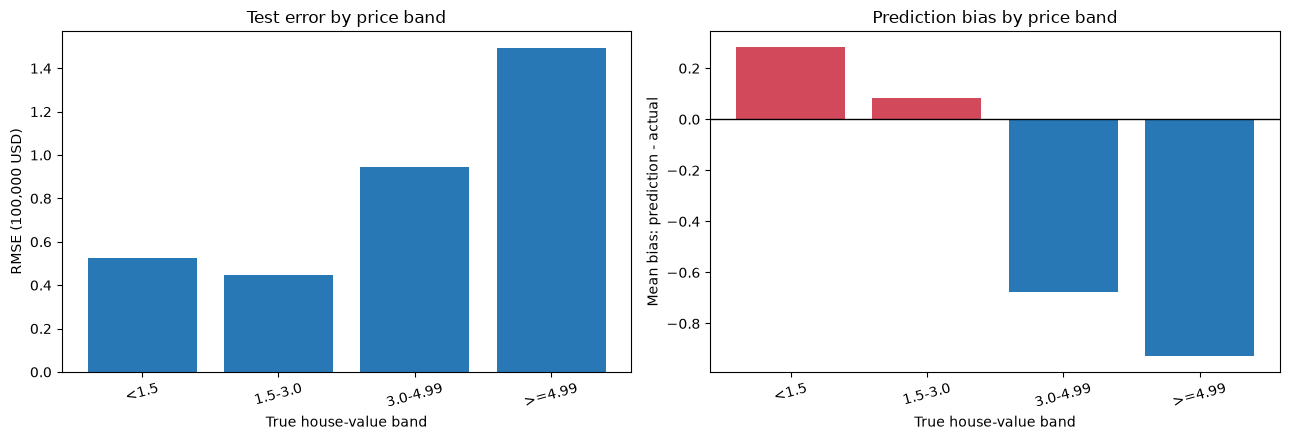

In [12]:
selected_test = prediction_frames[selected["key"]]["test"].copy()
selected_test["price_band"] = pd.cut(
    selected_test["y_true"],
    bins=[-np.inf, 1.5, 3.0, 4.99, np.inf],
    labels=["<1.5", "1.5-3.0", "3.0-4.99", ">=4.99"],
    right=False,
)
error_band = (
    selected_test.groupby("price_band", observed=True)
    .agg(
        n_samples=("residual", "size"),
        mae=("residual", lambda values: np.mean(np.abs(values))),
        rmse=("residual", lambda values: np.sqrt(np.mean(values**2))),
        mean_bias=("residual", lambda values: -np.mean(values)),
    )
    .reset_index()
)
display(error_band.round(4))
error_band.to_csv(QUICKSTART_DIR / "test_error_by_price_band.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].bar(error_band["price_band"].astype(str), error_band["rmse"], color="#2878B5")
axes[0].set_xlabel("True house-value band")
axes[0].set_ylabel("RMSE (100,000 USD)")
axes[0].set_title("Test error by price band")
axes[0].tick_params(axis="x", rotation=15)
colors = np.where(error_band["mean_bias"] >= 0, "#D1495B", "#2878B5")
axes[1].bar(error_band["price_band"].astype(str), error_band["mean_bias"], color=colors)
axes[1].axhline(0, color="black", linewidth=1)
axes[1].set_xlabel("True house-value band")
axes[1].set_ylabel("Mean bias: prediction - actual")
axes[1].set_title("Prediction bias by price band")
axes[1].tick_params(axis="x", rotation=15)
fig.tight_layout()
fig.savefig(QUICKSTART_DIR / "error_by_price_band.png", dpi=180, bbox_inches="tight")
plt.show()

In [13]:
manifest = {
    "random_state": RANDOM_STATE,
    "ridge_alpha_grid": RIDGE_ALPHAS,
    "selected_model": selected["key"],
    "selected_feature_set": selected["feature_set"],
    "selected_ridge_alpha": best_ridge["best_alpha"],
    "scratch_learning_rate": scratch_model.learning_rate,
    "scratch_iterations": scratch_model.n_iter_,
    "scratch_converged": scratch_model.converged_,
    "test_set_policy": "locked before final evaluation",
}
(QUICKSTART_DIR / "run_manifest.json").write_text(
    json.dumps(manifest, indent=2), encoding="utf-8"
)

print("Quickstart outputs:")
for path in sorted(QUICKSTART_DIR.rglob("*")):
    if path.is_file():
        print(f"- {path.relative_to(ROOT)}")
print("\nDone. See quickstart_results/ for metrics, predictions, and figures.")

Quickstart outputs:
- quickstart_results\eda_overview.png
- quickstart_results\error_by_price_band.png
- quickstart_results\feature_engineering_ablation.csv
- quickstart_results\feature_engineering_ablation.png
- quickstart_results\metrics.csv
- quickstart_results\numpy_ridge_loss.png
- quickstart_results\predictions\linear_ratio_test.csv
- quickstart_results\predictions\linear_ratio_validation.csv
- quickstart_results\predictions\linear_raw_test.csv
- quickstart_results\predictions\linear_raw_validation.csv
- quickstart_results\predictions\numpy_ridge_gd_test.csv
- quickstart_results\predictions\numpy_ridge_gd_validation.csv
- quickstart_results\predictions\ridge_ratio_test.csv
- quickstart_results\predictions\ridge_ratio_validation.csv
- quickstart_results\predictions\ridge_raw_test.csv
- quickstart_results\predictions\ridge_raw_validation.csv
- quickstart_results\ridge_alpha_selection.png
- quickstart_results\run_manifest.json
- quickstart_results\test_error_by_price_band.csv

Done.

## Next steps

- Use the same split files when adding Random Forest or boosted-tree models.
- Keep model selection on training/validation data and reserve the test set for one final evaluation.
- For the complete report assets, see `deliverables/`; for the full experiment script, run `python run_student_a.py`.

Results in this notebook are generated from real execution and should not be replaced with hand-entered values.